First 5 rows:
     0    1    2     3     4     5    6    7    8    9  ...   55   56   57  \
0  0.0  0.0  5.0  13.0   9.0   1.0  0.0  0.0  0.0  0.0  ...  0.0  0.0  0.0   
1  0.0  0.0  0.0  12.0  13.0   5.0  0.0  0.0  0.0  0.0  ...  0.0  0.0  0.0   
2  0.0  0.0  0.0   4.0  15.0  12.0  0.0  0.0  0.0  0.0  ...  0.0  0.0  0.0   
3  0.0  0.0  7.0  15.0  13.0   1.0  0.0  0.0  0.0  8.0  ...  0.0  0.0  0.0   
4  0.0  0.0  0.0   1.0  11.0   0.0  0.0  0.0  0.0  0.0  ...  0.0  0.0  0.0   

    58    59    60    61   62   63  target  
0  6.0  13.0  10.0   0.0  0.0  0.0       0  
1  0.0  11.0  16.0  10.0  0.0  0.0       1  
2  0.0   3.0  11.0  16.0  9.0  0.0       2  
3  7.0  13.0  13.0   9.0  0.0  0.0       3  
4  0.0   2.0  16.0   4.0  0.0  0.0       4  

[5 rows x 65 columns]

Accuracy: 0.975
Accuracy (%): 97.5

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.95      0.97      0.96        36
 

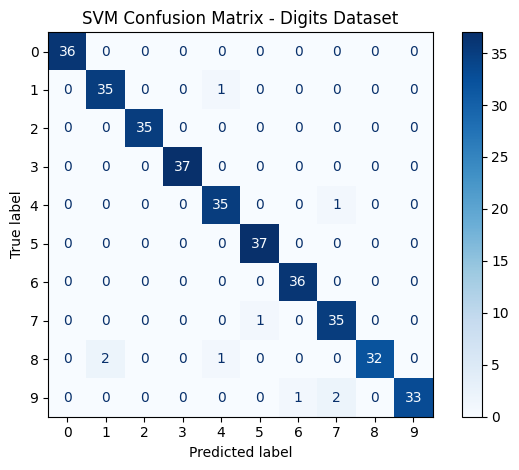


New Sample Prediction:
Predicted digit: 0

Prediction Probabilities:
0 : 99.34 %
1 : 0.02 %
2 : 0.03 %
3 : 0.07 %
4 : 0.05 %
5 : 0.09 %
6 : 0.04 %
7 : 0.06 %
8 : 0.05 %
9 : 0.24 %


In [ ]:
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.datasets import load_digits

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler

from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)


# Load the Digits dataset

digits = load_digits()

X = digits.data

y = digits.target


# Create DataFrame

df = pd.DataFrame(X)

df["target"] = y

print("First 5 rows:")

print(df.head())


# Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# Feature Scaling

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)


# Create Support Vector Classifier

model = SVC(
    kernel="rbf",
    probability=True,
    random_state=42
)


# Train the model

model.fit(X_train, y_train)


# Make predictions

y_pred = model.predict(X_test)


# Calculate accuracy

accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy:", accuracy)

print("Accuracy (%):", accuracy * 100)


# Classification Report

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred
    )
)


# Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")

print(cm)


# Display Confusion Matrix

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=digits.target_names
)

disp.plot(cmap="Blues")

plt.title("SVM Confusion Matrix - Digits Dataset")

plt.tight_layout()

plt.show()


# Predict a new sample

new_sample = [digits.data[0]]

new_sample = scaler.transform(new_sample)

prediction = model.predict(new_sample)

print("\nNew Sample Prediction:")

print("Predicted digit:", prediction[0])


# Prediction Probabilities

probabilities = model.predict_proba(new_sample)

print("\nPrediction Probabilities:")

for digit, probability in zip(
    digits.target_names,
    probabilities[0]
):

    print(
        digit,
        ":",
        round(probability * 100, 2),
        "%"
    )